# Laboratorio 07 Punto 2: 3D


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEMILLA = None
rng = np.random.default_rng(SEMILLA)

**Link Repositorio:** https://github.com/jccondoric/machine_learning/blob/master/Laboratorios/Laboratorio_7/Laboratorio7Punto2.ipynb <br>
**Link del Video explicacion:**
https://drive.google.com/drive/folders/1-UtIun_IGB90EDH2UhZgpNhR1LMiNFAC?usp=sharing<br>

### Posiciones aleatorias de los centroides con distancia mínima (3D)

In [2]:
def generar_centroides(n_centros, lado=50.0, dist_min=12.0, max_intentos=100000):
    centros = []
    intentos = 0
    while len(centros) < n_centros:
        candidato = rng.uniform(-lado, lado, size=3)
        if all(np.linalg.norm(candidato - c) > dist_min for c in centros):
            centros.append(candidato)
        intentos += 1
        if intentos > max_intentos:
            raise RuntimeError("No caben tantos centros: aumenta lado o reduce dist_min")
    return np.array(centros)

### Generador del dataset 3D: cantidad, dispersión y puntos por centroide

In [3]:
def generar_dataset(n_centros=None, lado=50.0, dist_min=12.0, pts_min=50, pts_max=300):
    if n_centros is None:
        n_centros = int(rng.integers(1, 21))

    centros = generar_centroides(n_centros, lado, dist_min)
    std_max = dist_min / 5
    desviaciones = rng.uniform(0.5, std_max, size=n_centros)
    puntos_por_centro = rng.integers(pts_min, pts_max + 1, size=n_centros)

    X, y = make_blobs(n_samples=list(puntos_por_centro), centers=centros,
                      cluster_std=desviaciones,
                      random_state=int(rng.integers(0, 10**6)))
    return X, y, centros, desviaciones, puntos_por_centro

### Generar el dataset y ver sus parámetros

In [4]:
X, y_real, centros_reales, desv, n_reales = generar_dataset()
k = len(centros_reales)

print(f"Centroides generados : {k}")
print(f"Forma de X           : {X.shape}")
print("Puntos por centroide :", n_reales.tolist())
print("Desviaciones         :", np.round(desv, 2).tolist())

Centroides generados : 2
Forma de X           : (390, 3)
Puntos por centroide : [116, 274]
Desviaciones         : [1.05, 1.49]


### Función de estilo para ejes 3D

In [5]:
cmap = plt.get_cmap("tab20")

def estilo_3d(ax, titulo):
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_zlabel("$x_3$")
    ax.set_title(titulo)
    ax.set_box_aspect((1, 1, 1))

### Gráfico 1: el dataset generado

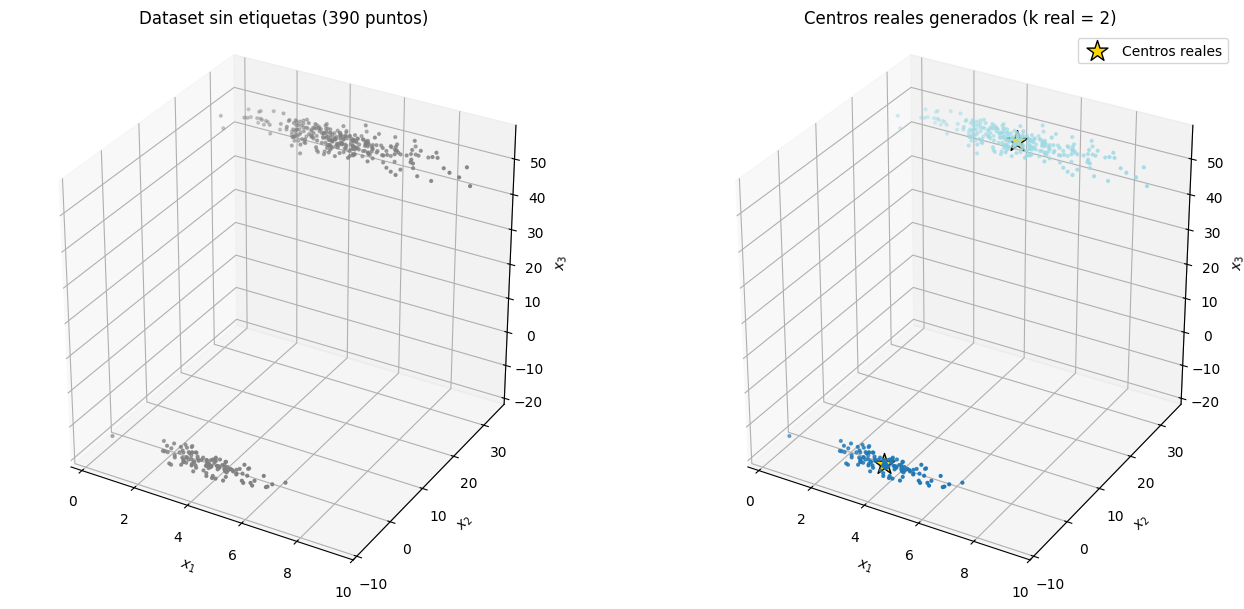

In [6]:
fig = plt.figure(figsize=(14, 6))

ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=4, c="gray")
estilo_3d(ax, f"Dataset sin etiquetas ({len(X)} puntos)")

ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=4, c=y_real, cmap="tab20")
ax.scatter(centros_reales[:, 0], centros_reales[:, 1], centros_reales[:, 2],
           marker="*", s=250, c="gold", edgecolors="k", depthshade=False,
           label="Centros reales")
estilo_3d(ax, f"Centros reales generados (k real = {k})")
ax.legend()

plt.tight_layout()
plt.savefig("p2_01_dataset.png", dpi=120)
plt.show()

### Gráfico 2: el proceso iterativo de K-Means



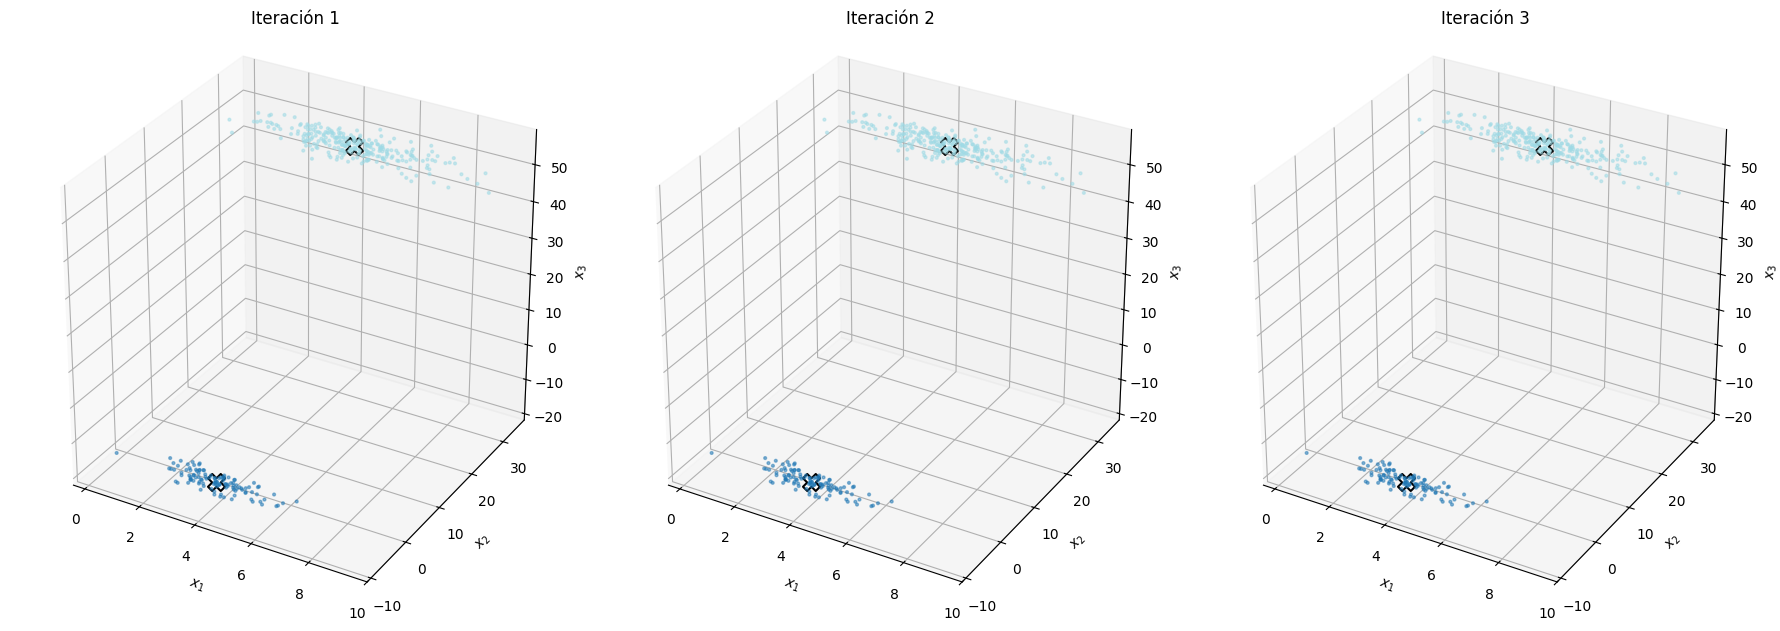

In [7]:
iters = [KMeans(n_clusters=k, init="k-means++", n_init=1, algorithm="lloyd",
                max_iter=m, random_state=1).fit(X) for m in (1, 2, 3)]

fig = plt.figure(figsize=(18, 6))
for i, modelo in enumerate(iters):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=modelo.labels_, cmap="tab20", s=4, alpha=0.5)
    c = modelo.cluster_centers_
    ax.scatter(c[:, 0], c[:, 1], c[:, 2], marker="X", s=150, c="white",
               edgecolors="k", linewidths=1.5, depthshade=False)
    estilo_3d(ax, f"Iteración {i + 1}")
plt.tight_layout()
plt.savefig("p2_02_iteraciones.png", dpi=120)
plt.show()

### Aplicar K-Means: ubicación final de los centroides



In [8]:
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
etiquetas = kmeans.fit_predict(X)
centroides = kmeans.cluster_centers_

### Número de puntos por centroide y los 5 más cercanos

In [9]:
conteo = np.bincount(etiquetas, minlength=k)

distancias = kmeans.transform(X)
cercanos = {}
for j in range(k):
    idx_cluster = np.where(etiquetas == j)[0]
    orden = np.argsort(distancias[idx_cluster, j])[:5]
    cercanos[j] = idx_cluster[orden]

### Resultados en texto

In [10]:
print(f"Inercia final: {kmeans.inertia_:.2f}")
for j in range(k):
    print(f"\nCentroide {j}: ({centroides[j, 0]:.2f}, {centroides[j, 1]:.2f}, {centroides[j, 2]:.2f})"
          f" | puntos: {conteo[j]}")
    for rango, i in enumerate(cercanos[j], start=1):
        print(f"   {rango}. índice {i:4d}  punto ({X[i, 0]:.2f}, {X[i, 1]:.2f}, {X[i, 2]:.2f})"
              f"  distancia {distancias[i, j]:.3f}")

err = [np.min(np.linalg.norm(centroides - c, axis=1)) for c in centros_reales]
print(f"\nError medio entre centros reales y centroides estimados: {np.mean(err):.3f}")

Inercia final: 2280.42

Centroide 0: (4.49, 29.89, 49.40) | puntos: 274
   1. índice  347  punto (4.31, 29.73, 49.50)  distancia 0.249
   2. índice   57  punto (4.22, 29.66, 49.26)  distancia 0.374
   3. índice  335  punto (4.58, 30.16, 49.71)  distancia 0.426
   4. índice  199  punto (4.87, 30.04, 49.12)  distancia 0.499
   5. índice  243  punto (4.58, 29.55, 48.99)  distancia 0.539

Centroide 1: (4.06, -5.61, -14.65) | puntos: 116
   1. índice  123  punto (4.10, -5.71, -14.47)  distancia 0.211
   2. índice  283  punto (4.02, -5.64, -14.96)  distancia 0.319
   3. índice   65  punto (4.38, -5.54, -14.55)  distancia 0.341
   4. índice  197  punto (4.41, -5.61, -14.45)  distancia 0.401
   5. índice  173  punto (4.16, -5.52, -15.12)  distancia 0.494

Error medio entre centros reales y centroides estimados: 0.169


### Gráfico 3: resultado final



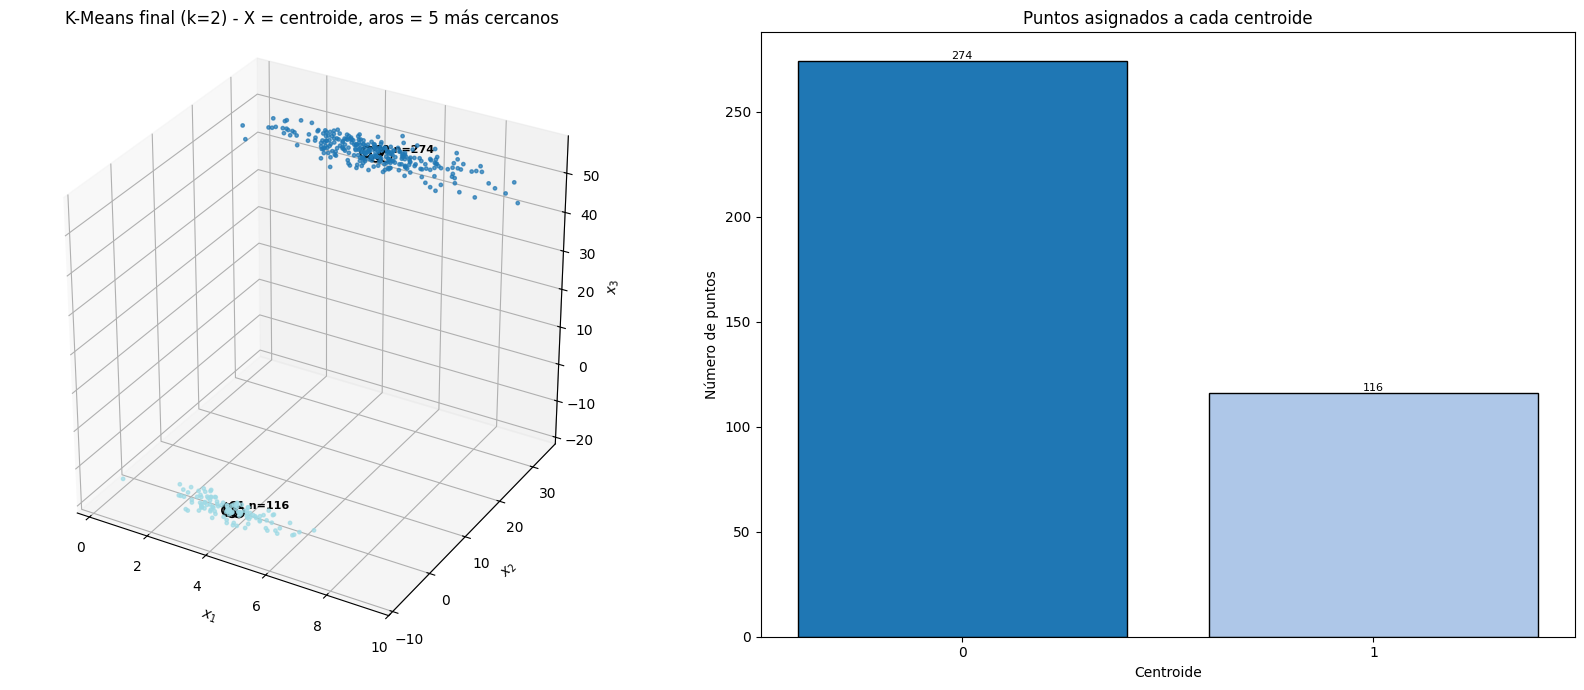

In [11]:
fig = plt.figure(figsize=(17, 7))

a = fig.add_subplot(1, 2, 1, projection="3d")
a.scatter(X[:, 0], X[:, 1], X[:, 2], c=etiquetas, cmap="tab20", s=6, alpha=0.7)
for j in range(k):
    idx = cercanos[j]
    a.scatter(X[idx, 0], X[idx, 1], X[idx, 2], s=60, facecolors="none",
              edgecolors="k", linewidths=1.2, depthshade=False)
a.scatter(centroides[:, 0], centroides[:, 1], centroides[:, 2], marker="X", s=90,
          c="white", edgecolors="k", linewidths=1.2, depthshade=False)
for j in range(k):
    a.text(centroides[j, 0], centroides[j, 1], centroides[j, 2],
           f"C{j} n={conteo[j]}", fontsize=8, fontweight="bold")
estilo_3d(a, f"K-Means final (k={k}) - X = centroide, aros = 5 más cercanos")

b = fig.add_subplot(1, 2, 2)
b.bar(range(k), conteo, color=[cmap(j % 20) for j in range(k)], edgecolor="k")
b.set_xticks(range(k))
b.set_xlabel("Centroide")
b.set_ylabel("Número de puntos")
b.set_title("Puntos asignados a cada centroide")
for j in range(k):
    b.text(j, conteo[j], str(conteo[j]), ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig("p2_03_resultado_final.png", dpi=120)
plt.show()

### Gráfico 4: silueta vs número de clusters


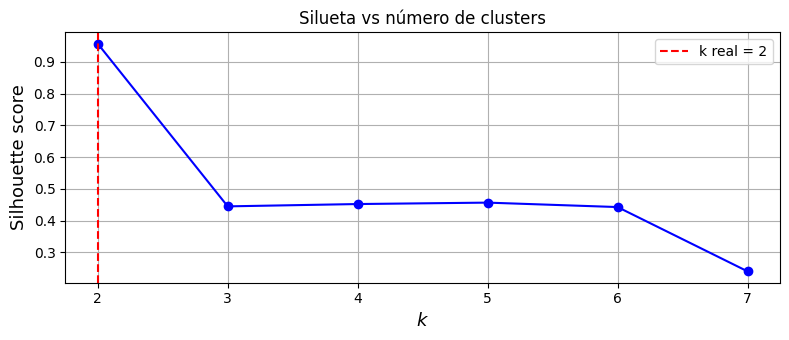

Mejor k según silueta: 2  (k real: 2)


In [12]:
if k >= 2:
    max_k = min(20, k + 5)
    ks = list(range(2, max_k + 1))
    modelos = [KMeans(n_clusters=kk, n_init=10, random_state=42).fit(X) for kk in ks]
    sil = [silhouette_score(X, m.labels_) for m in modelos]

    plt.figure(figsize=(8, 3.5))
    plt.plot(ks, sil, "bo-")
    plt.axvline(k, color="r", linestyle="--", label=f"k real = {k}")
    plt.xlabel("$k$", fontsize=13)
    plt.ylabel("Silhouette score", fontsize=13)
    plt.title("Silueta vs número de clusters")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig("p2_04_silueta.png", dpi=120)
    plt.show()
    print(f"Mejor k según silueta: {ks[int(np.argmax(sil))]}  (k real: {k})")
else:
    print("Con k=1 no se puede calcular la silueta (necesita al menos 2 clusters).")

### Gráfico 5: zoom por centroide


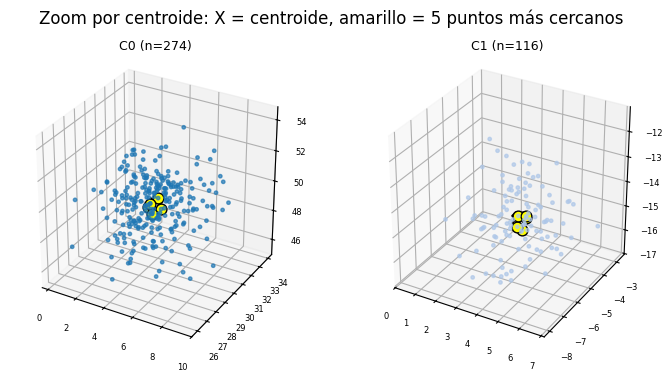

In [13]:
cols = min(5, k)
filas = int(np.ceil(k / cols))
fig = plt.figure(figsize=(3.6 * cols, 3.6 * filas))
for j in range(k):
    a = fig.add_subplot(filas, cols, j + 1, projection="3d")
    pts = X[etiquetas == j]
    a.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=6, color=cmap(j % 20), alpha=0.7)
    c5 = X[cercanos[j]]
    a.scatter(c5[:, 0], c5[:, 1], c5[:, 2], s=60, color="yellow",
              edgecolors="k", depthshade=False)
    a.scatter(*centroides[j], marker="X", s=110, c="white", edgecolors="k",
              linewidths=1.5, depthshade=False)
    a.set_title(f"C{j} (n={conteo[j]})", fontsize=9)
    a.tick_params(labelsize=6)
    a.set_box_aspect((1, 1, 1))
plt.suptitle("Zoom por centroide: X = centroide, amarillo = 5 puntos más cercanos")
plt.tight_layout()
plt.savefig("p2_05_zoom_por_centroide.png", dpi=110)
plt.show()